# Train ASL Landmark Classifier

This notebook trains the 56-sign classifier from `selected_landmarks/` and keeps `train`, `val`, and `test` roles separate. There are 5 different architectures. Validation drives the short hyperparameter sweep, LR scheduling, checkpointing, and early stopping; the test set is evaluated once at the end using the selected best checkpoint.


In [1]:
from pathlib import Path
import copy
import math
import pickle
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **kwargs: x

SEED = 42
LANDMARK_DIR = Path('selected_landmarks')
MODEL_DIR = Path('models')
MODEL_DIR.mkdir(exist_ok=True)

EXPECTED_SEQUENCE_LENGTH = 30
EXPECTED_FEATURE_COUNT = 315
EXPECTED_NUM_CLASSES = 56

# Full final-training defaults. For a quick notebook smoke test, set
# SMOKE_TEST = True; it will use 2 epochs, patience 2, and only config 1.
SMOKE_TEST = False
NUM_EPOCHS = 120
PATIENCE = 20
RUN_CONFIG_LIMIT = None

if SMOKE_TEST:
    NUM_EPOCHS = 2
    PATIENCE = 2
    RUN_CONFIG_LIMIT = 1

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)
print('Smoke test mode:', SMOKE_TEST)


Using device: cpu
Smoke test mode: False


c:\Users\fores\AppData\Local\Programs\Python\Python39\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def load_split(split):
    X = np.load(LANDMARK_DIR / f'{split}_X.npy').astype(np.float32)
    y = np.load(LANDMARK_DIR / f'{split}_y.npy').astype(np.int64)
    return X, y

train_X, train_y = load_split('train')
val_X, val_y = load_split('val')
test_X, test_y = load_split('test')

with open(LANDMARK_DIR / 'label_to_id.pkl', 'rb') as f:
    label_to_id = pickle.load(f)

with open(LANDMARK_DIR / 'landmark_selection.pkl', 'rb') as f:
    landmark_selection = pickle.load(f)

id_to_label = {idx: label for label, idx in label_to_id.items()}
num_classes = len(label_to_id)
input_size = train_X.shape[-1]
sequence_length = train_X.shape[1]

print('train_X:', train_X.shape, 'train_y:', train_y.shape)
print('val_X:  ', val_X.shape, 'val_y:  ', val_y.shape)
print('test_X: ', test_X.shape, 'test_y: ', test_y.shape)
print('labels:', label_to_id)
print('input_size:', input_size, 'sequence_length:', sequence_length)

def validate_split(name, X, y):
    if X.ndim != 3:
        raise ValueError(f'{name}_X must be 3D, got shape {X.shape}')
    if X.shape[1] != EXPECTED_SEQUENCE_LENGTH:
        raise ValueError(f'{name}_X sequence length must be {EXPECTED_SEQUENCE_LENGTH}, got {X.shape[1]}')
    if X.shape[2] != EXPECTED_FEATURE_COUNT:
        raise ValueError(f'{name}_X feature count must be {EXPECTED_FEATURE_COUNT}, got {X.shape[2]}')
    if len(X) != len(y):
        raise ValueError(f'{name}_X and {name}_y length mismatch: {len(X)} vs {len(y)}')
    bad_ids = sorted(set(map(int, y.tolist())) - set(id_to_label.keys()))
    if bad_ids:
        raise ValueError(f'{name}_y contains label ids not in label_to_id: {bad_ids}')

for split_name, X, y in [('train', train_X, train_y), ('val', val_X, val_y), ('test', test_X, test_y)]:
    validate_split(split_name, X, y)

if num_classes != EXPECTED_NUM_CLASSES:
    raise ValueError(f'Expected exactly {EXPECTED_NUM_CLASSES} classes, got {num_classes}')
if landmark_selection.get('selected_feature_count') != EXPECTED_FEATURE_COUNT:
    raise ValueError('landmark_selection.pkl does not describe 315 selected features')
if landmark_selection.get('sequence_length') != EXPECTED_SEQUENCE_LENGTH:
    raise ValueError('landmark_selection.pkl does not describe sequence length 30')

counts = []
for split_name, y in [('train', train_y), ('val', val_y), ('test', test_y)]:
    split_counts = pd.Series(y).map(id_to_label).value_counts().reindex(label_to_id.keys(), fill_value=0)
    counts.append(split_counts.rename(split_name))

display(pd.concat(counts, axis=1).astype(int))
print('Validation checks passed.')


train_X: (3113, 30, 315) train_y: (3113,)
val_X:   (536, 30, 315) val_y:   (536,)
test_X:  (536, 30, 315) test_y:  (536,)
labels: {'again': 0, 'bad': 1, 'bathroom': 2, 'book': 3, 'bye': 4, "don't know": 5, "don't like": 6, "don't understand": 7, "don't want": 8, 'drink': 9, 'eat': 10, 'family': 11, 'father': 12, 'finish': 13, 'friend': 14, 'go': 15, 'good': 16, 'happy': 17, 'have': 18, 'he': 19, 'hello': 20, 'help': 21, 'home': 22, 'know': 23, 'like': 24, 'me': 25, 'more': 26, 'mother': 27, 'name': 28, 'need': 29, 'no': 30, 'not': 31, 'now': 32, 'play': 33, 'please': 34, 'sad': 35, 'same': 36, 'school': 37, 'sit': 38, 'sorry': 39, 'stop': 40, 'thank you': 41, 'they': 42, 'think': 43, 'tired': 44, 'understand': 45, 'want': 46, 'water': 47, 'we': 48, 'what': 49, 'which': 50, 'who': 51, 'why': 52, 'work': 53, 'yes': 54, 'you': 55}
input_size: 315 sequence_length: 30


,train,val,test
again,63,7,7
bad,51,5,5
bathroom,77,13,13
book,59,8,8
bye,41,6,6
don't know,22,5,4
don't like,44,9,9
don't understand,58,10,10
don't want,25,5,5
drink,80,11,12


Validation checks passed.


In [4]:
# Standardize using train-set statistics only. Missing landmarks are zeros, so compute
# stats from nonzero values per feature and keep missing zeros as zeros after scaling.
feature_mean = np.zeros((input_size,), dtype=np.float32)
feature_std = np.ones((input_size,), dtype=np.float32)
flat_train = train_X.reshape(-1, input_size)
nonzero_mask = flat_train != 0

for feature_idx in range(input_size):
    values = flat_train[nonzero_mask[:, feature_idx], feature_idx]
    if len(values) > 1:
        feature_mean[feature_idx] = values.mean()
        feature_std[feature_idx] = max(values.std(), 1e-6)


def apply_standardization(X, mean, std):
    X = X.copy().astype(np.float32)
    mask = X != 0
    X[mask] = ((X - mean) / std)[mask]
    return X

train_X_norm = apply_standardization(train_X, feature_mean, feature_std)
val_X_norm = apply_standardization(val_X, feature_mean, feature_std)
test_X_norm = apply_standardization(test_X, feature_mean, feature_std)

print('Standardized train/val/test arrays using train-set statistics only.')


Standardized train/val/test arrays using train-set statistics only.


In [5]:
def resample_sequence(sequence, target_length):
    sequence = np.asarray(sequence, dtype=np.float32)
    if len(sequence) == target_length:
        return sequence
    if len(sequence) == 0:
        return np.zeros((target_length, input_size), dtype=np.float32)
    if len(sequence) == 1:
        return np.repeat(sequence, target_length, axis=0)

    source_positions = np.linspace(0, len(sequence) - 1, num=len(sequence))
    target_positions = np.linspace(0, len(sequence) - 1, num=target_length)
    out = np.empty((target_length, sequence.shape[1]), dtype=np.float32)
    for feature_idx in range(sequence.shape[1]):
        out[:, feature_idx] = np.interp(target_positions, source_positions, sequence[:, feature_idx])
    return out


class LandmarkAugmenter:
    def __init__(self, noise_std=0.015, scale_range=(0.95, 1.05), shift_std=0.02, frame_drop_prob=0.05):
        self.noise_std = noise_std
        self.scale_range = scale_range
        self.shift_std = shift_std
        self.frame_drop_prob = frame_drop_prob

    def __call__(self, sequence):
        sequence = sequence.copy()
        detected = sequence != 0

        if self.noise_std > 0:
            noise = np.random.normal(0, self.noise_std, sequence.shape).astype(np.float32)
            sequence[detected] += noise[detected]

        scale = np.random.uniform(*self.scale_range)
        sequence[detected] *= scale

        shifts = np.random.normal(0, self.shift_std, size=(3,)).astype(np.float32)
        for coord in range(3):
            coord_mask = detected[:, coord::3]
            coord_values = sequence[:, coord::3]
            coord_values[coord_mask] += shifts[coord]
            sequence[:, coord::3] = coord_values

        if self.frame_drop_prob > 0 and len(sequence) > 2:
            drop_mask = np.random.rand(len(sequence)) < self.frame_drop_prob
            keep_indices = np.where(~drop_mask)[0]
            if len(keep_indices) > 1:
                sequence = resample_sequence(sequence[keep_indices], len(drop_mask))

        return sequence.astype(np.float32)


class LandmarkDataset(Dataset):
    def __init__(self, X, y, augment=False):
        self.X = X.astype(np.float32)
        self.y = y.astype(np.int64)
        self.augmenter = LandmarkAugmenter() if augment else None

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        sequence = self.X[idx]
        if self.augmenter is not None:
            sequence = self.augmenter(sequence)
        return torch.from_numpy(sequence), torch.tensor(self.y[idx], dtype=torch.long)


def make_loaders(batch_size, augment_train=True):
    train_dataset = LandmarkDataset(train_X_norm, train_y, augment=augment_train)
    val_dataset = LandmarkDataset(val_X_norm, val_y, augment=False)
    test_dataset = LandmarkDataset(test_X_norm, test_y, augment=False)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, drop_last=False)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, drop_last=False)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, drop_last=False)
    return train_loader, val_loader, test_loader

sample_train_loader, _, _ = make_loaders(batch_size=16, augment_train=True)
batch_X, batch_y = next(iter(sample_train_loader))
print('Batch X:', batch_X.shape, 'Batch y:', batch_y.shape)


Batch X: torch.Size([16, 30, 315]) Batch y: torch.Size([16])


## Model Families

This section defines the actual candidate architectures: **BiLSTM attention**, **BiGRU attention**, **residual TCN**, **small Transformer**, and **Conv+GRU attention**. The checkpoint stores `model_type` and `model_config` so inference can rebuild whichever architecture wins.


In [6]:
class AttentionPool(nn.Module):
    def __init__(self, hidden_dim):
        super().__init__()
        self.score = nn.Sequential(
            nn.Linear(hidden_dim, max(hidden_dim // 2, 1)),
            nn.Tanh(),
            nn.Linear(max(hidden_dim // 2, 1), 1),
        )

    def forward(self, sequence):
        weights = self.score(sequence).squeeze(-1)
        weights = torch.softmax(weights, dim=1).unsqueeze(-1)
        return torch.sum(sequence * weights, dim=1)


class MeanMaxPool(nn.Module):
    def forward(self, sequence):
        return torch.cat([sequence.mean(dim=1), sequence.max(dim=1).values], dim=1)


class PositionalEncoding(nn.Module):
    def __init__(self, dim, max_len=128):
        super().__init__()
        position = torch.arange(max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, dim, 2, dtype=torch.float32) * (-math.log(10000.0) / dim))
        pe = torch.zeros(max_len, dim, dtype=torch.float32)
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term[:pe[:, 1::2].shape[1]])
        self.register_buffer('pe', pe.unsqueeze(0))

    def forward(self, x):
        return x + self.pe[:, :x.size(1)]


class SignLSTMClassifier(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes, dropout=0.35, num_layers=2):
        super().__init__()
        self.input_norm = nn.LayerNorm(input_size)
        self.input_dropout = nn.Dropout(dropout)
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.attention = AttentionPool(hidden_size * 2)
        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden_size * 2),
            nn.Dropout(dropout),
            nn.Linear(hidden_size * 2, hidden_size),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, num_classes),
        )

    def forward(self, x):
        x = self.input_norm(x)
        x = self.input_dropout(x)
        output, _ = self.lstm(x)
        pooled = self.attention(output)
        return self.classifier(pooled)


class SignGRUClassifier(nn.Module):
    def __init__(self, input_size, hidden_size, num_classes, dropout=0.35, num_layers=2):
        super().__init__()
        self.input_norm = nn.LayerNorm(input_size)
        self.input_dropout = nn.Dropout(dropout)
        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.attention = AttentionPool(hidden_size * 2)
        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden_size * 2),
            nn.Dropout(dropout),
            nn.Linear(hidden_size * 2, hidden_size),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, num_classes),
        )

    def forward(self, x):
        x = self.input_norm(x)
        x = self.input_dropout(x)
        output, _ = self.gru(x)
        pooled = self.attention(output)
        return self.classifier(pooled)


class TemporalResidualBlock(nn.Module):
    def __init__(self, channels, kernel_size=3, dilation=1, dropout=0.25):
        super().__init__()
        padding = dilation * (kernel_size - 1) // 2
        self.net = nn.Sequential(
            nn.Conv1d(channels, channels, kernel_size, padding=padding, dilation=dilation),
            nn.BatchNorm1d(channels),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Conv1d(channels, channels, kernel_size, padding=padding, dilation=dilation),
            nn.BatchNorm1d(channels),
        )
        self.activation = nn.GELU()

    def forward(self, x):
        return self.activation(x + self.net(x))


class SignTCNClassifier(nn.Module):
    def __init__(self, input_size, channels, num_classes, dropout=0.30, num_blocks=4):
        super().__init__()
        self.input_norm = nn.LayerNorm(input_size)
        self.input_projection = nn.Conv1d(input_size, channels, kernel_size=1)
        dilations = [2 ** (idx % 3) for idx in range(num_blocks)]
        self.blocks = nn.Sequential(*[
            TemporalResidualBlock(channels, dilation=dilation, dropout=dropout)
            for dilation in dilations
        ])
        self.classifier = nn.Sequential(
            nn.LayerNorm(channels * 2),
            nn.Dropout(dropout),
            nn.Linear(channels * 2, channels),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(channels, num_classes),
        )

    def forward(self, x):
        x = self.input_norm(x).transpose(1, 2)
        x = self.input_projection(x)
        x = self.blocks(x).transpose(1, 2)
        pooled = torch.cat([x.mean(dim=1), x.max(dim=1).values], dim=1)
        return self.classifier(pooled)


class SignTransformerClassifier(nn.Module):
    def __init__(self, input_size, model_dim, num_classes, dropout=0.30, num_layers=2, num_heads=4, ff_mult=4):
        super().__init__()
        self.input_norm = nn.LayerNorm(input_size)
        self.projection = nn.Linear(input_size, model_dim)
        self.position = PositionalEncoding(model_dim, max_len=EXPECTED_SEQUENCE_LENGTH)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=model_dim,
            nhead=num_heads,
            dim_feedforward=model_dim * ff_mult,
            dropout=dropout,
            activation='gelu',
            batch_first=True,
            norm_first=True,
        )
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)
        self.pool = AttentionPool(model_dim)
        self.classifier = nn.Sequential(
            nn.LayerNorm(model_dim),
            nn.Dropout(dropout),
            nn.Linear(model_dim, model_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(model_dim, num_classes),
        )

    def forward(self, x):
        x = self.input_norm(x)
        x = self.projection(x)
        x = self.position(x)
        x = self.encoder(x)
        pooled = self.pool(x)
        return self.classifier(pooled)


class SignConvGRUClassifier(nn.Module):
    def __init__(self, input_size, conv_channels, hidden_size, num_classes, dropout=0.35, num_layers=1):
        super().__init__()
        self.input_norm = nn.LayerNorm(input_size)
        self.conv = nn.Sequential(
            nn.Conv1d(input_size, conv_channels, kernel_size=3, padding=1),
            nn.BatchNorm1d(conv_channels),
            nn.GELU(),
            nn.Dropout(dropout),
            TemporalResidualBlock(conv_channels, dilation=2, dropout=dropout),
        )
        self.gru = nn.GRU(
            input_size=conv_channels,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=True,
            dropout=dropout if num_layers > 1 else 0.0,
        )
        self.attention = AttentionPool(hidden_size * 2)
        self.classifier = nn.Sequential(
            nn.LayerNorm(hidden_size * 2),
            nn.Dropout(dropout),
            nn.Linear(hidden_size * 2, hidden_size),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, num_classes),
        )

    def forward(self, x):
        x = self.input_norm(x).transpose(1, 2)
        x = self.conv(x).transpose(1, 2)
        output, _ = self.gru(x)
        pooled = self.attention(output)
        return self.classifier(pooled)


MODEL_REGISTRY = {
    'bilstm_attention': SignLSTMClassifier,
    'bigru_attention': SignGRUClassifier,
    'tcn': SignTCNClassifier,
    'transformer': SignTransformerClassifier,
    'conv_gru_attention': SignConvGRUClassifier,
}


def build_model(config):
    model_type = config['model_type']
    model_kwargs = copy.deepcopy(config['model_kwargs'])
    model_class = MODEL_REGISTRY[model_type]
    return model_class(input_size=input_size, num_classes=num_classes, **model_kwargs)

expected_model_types = {
    'bilstm_attention',
    'bigru_attention',
    'tcn',
    'transformer',
    'conv_gru_attention',
}
if set(MODEL_REGISTRY) != expected_model_types:
    raise ValueError(f'MODEL_REGISTRY mismatch: {MODEL_REGISTRY.keys()}')

build_model({
    'model_type': 'bilstm_attention',
    'model_kwargs': {'hidden_size': 128, 'dropout': 0.35, 'num_layers': 2},
})


SignLSTMClassifier(
  (input_norm): LayerNorm((315,), eps=1e-05, elementwise_affine=True)
  (input_dropout): Dropout(p=0.35, inplace=False)
  (lstm): LSTM(315, 128, num_layers=2, batch_first=True, dropout=0.35, bidirectional=True)
  (attention): AttentionPool(
    (score): Sequential(
      (0): Linear(in_features=256, out_features=128, bias=True)
      (1): Tanh()
      (2): Linear(in_features=128, out_features=1, bias=True)
    )
  )
  (classifier): Sequential(
    (0): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    (1): Dropout(p=0.35, inplace=False)
    (2): Linear(in_features=256, out_features=128, bias=True)
    (3): GELU(approximate='none')
    (4): Dropout(p=0.35, inplace=False)
    (5): Linear(in_features=128, out_features=56, bias=True)
  )
)

In [7]:
class_counts = np.bincount(train_y, minlength=num_classes)
class_weights_np = class_counts.sum() / np.maximum(class_counts, 1)
class_weights_np = class_weights_np / class_weights_np.mean()
class_weights = torch.tensor(class_weights_np, dtype=torch.float32, device=device)

print('Class counts:', class_counts.tolist())
print('Class weights:', class_weights.detach().cpu().numpy().round(3).tolist())

COMMON_TRAINING = {
    'augment_train': True,
    'label_smoothing': 0.05,
}

CONFIGS = [
    # BiLSTM + attention baseline.
    {'config_name': 'lstm_baseline_128', 'model_type': 'bilstm_attention', 'model_kwargs': {'hidden_size': 128, 'dropout': 0.35, 'num_layers': 2}, 'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 16, **COMMON_TRAINING},
    {'config_name': 'lstm_wider_160', 'model_type': 'bilstm_attention', 'model_kwargs': {'hidden_size': 160, 'dropout': 0.35, 'num_layers': 2}, 'learning_rate': 8e-4, 'weight_decay': 1e-4, 'batch_size': 16, **COMMON_TRAINING},
    {'config_name': 'lstm_regularized_128', 'model_type': 'bilstm_attention', 'model_kwargs': {'hidden_size': 128, 'dropout': 0.45, 'num_layers': 2}, 'learning_rate': 8e-4, 'weight_decay': 3e-4, 'batch_size': 16, 'augment_train': True, 'label_smoothing': 0.08},
    {'config_name': 'lstm_small_batch_128', 'model_type': 'bilstm_attention', 'model_kwargs': {'hidden_size': 128, 'dropout': 0.30, 'num_layers': 2}, 'learning_rate': 7e-4, 'weight_decay': 1e-4, 'batch_size': 8, **COMMON_TRAINING},

    # BiGRU + attention.
    {'config_name': 'gru_baseline_128', 'model_type': 'bigru_attention', 'model_kwargs': {'hidden_size': 128, 'dropout': 0.35, 'num_layers': 2}, 'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 16, **COMMON_TRAINING},
    {'config_name': 'gru_wider_160', 'model_type': 'bigru_attention', 'model_kwargs': {'hidden_size': 160, 'dropout': 0.35, 'num_layers': 2}, 'learning_rate': 8e-4, 'weight_decay': 1e-4, 'batch_size': 16, **COMMON_TRAINING},
    {'config_name': 'gru_regularized_128', 'model_type': 'bigru_attention', 'model_kwargs': {'hidden_size': 128, 'dropout': 0.45, 'num_layers': 2}, 'learning_rate': 8e-4, 'weight_decay': 3e-4, 'batch_size': 16, 'augment_train': True, 'label_smoothing': 0.08},
    {'config_name': 'gru_small_batch_128', 'model_type': 'bigru_attention', 'model_kwargs': {'hidden_size': 128, 'dropout': 0.30, 'num_layers': 2}, 'learning_rate': 7e-4, 'weight_decay': 1e-4, 'batch_size': 8, **COMMON_TRAINING},

    # Residual temporal CNN.
    {'config_name': 'tcn_baseline_128', 'model_type': 'tcn', 'model_kwargs': {'channels': 128, 'dropout': 0.30, 'num_blocks': 4}, 'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 16, **COMMON_TRAINING},
    {'config_name': 'tcn_wider_160', 'model_type': 'tcn', 'model_kwargs': {'channels': 160, 'dropout': 0.30, 'num_blocks': 4}, 'learning_rate': 8e-4, 'weight_decay': 1e-4, 'batch_size': 16, **COMMON_TRAINING},
    {'config_name': 'tcn_deeper_128', 'model_type': 'tcn', 'model_kwargs': {'channels': 128, 'dropout': 0.35, 'num_blocks': 6}, 'learning_rate': 8e-4, 'weight_decay': 2e-4, 'batch_size': 16, **COMMON_TRAINING},
    {'config_name': 'tcn_regularized_128', 'model_type': 'tcn', 'model_kwargs': {'channels': 128, 'dropout': 0.45, 'num_blocks': 4}, 'learning_rate': 7e-4, 'weight_decay': 3e-4, 'batch_size': 8, 'augment_train': True, 'label_smoothing': 0.08},

    # Small transformer encoder.
    {'config_name': 'transformer_baseline_128', 'model_type': 'transformer', 'model_kwargs': {'model_dim': 128, 'dropout': 0.30, 'num_layers': 2, 'num_heads': 4, 'ff_mult': 4}, 'learning_rate': 8e-4, 'weight_decay': 1e-4, 'batch_size': 16, **COMMON_TRAINING},
    {'config_name': 'transformer_wider_160', 'model_type': 'transformer', 'model_kwargs': {'model_dim': 160, 'dropout': 0.30, 'num_layers': 2, 'num_heads': 4, 'ff_mult': 4}, 'learning_rate': 6e-4, 'weight_decay': 1e-4, 'batch_size': 16, **COMMON_TRAINING},
    {'config_name': 'transformer_deeper_128', 'model_type': 'transformer', 'model_kwargs': {'model_dim': 128, 'dropout': 0.35, 'num_layers': 3, 'num_heads': 4, 'ff_mult': 4}, 'learning_rate': 6e-4, 'weight_decay': 2e-4, 'batch_size': 16, **COMMON_TRAINING},
    {'config_name': 'transformer_regularized_128', 'model_type': 'transformer', 'model_kwargs': {'model_dim': 128, 'dropout': 0.45, 'num_layers': 2, 'num_heads': 4, 'ff_mult': 3}, 'learning_rate': 5e-4, 'weight_decay': 3e-4, 'batch_size': 8, 'augment_train': True, 'label_smoothing': 0.08},

    # Temporal convolution front-end plus BiGRU attention.
    {'config_name': 'conv_gru_baseline', 'model_type': 'conv_gru_attention', 'model_kwargs': {'conv_channels': 128, 'hidden_size': 128, 'dropout': 0.35, 'num_layers': 1}, 'learning_rate': 1e-3, 'weight_decay': 1e-4, 'batch_size': 16, **COMMON_TRAINING},
    {'config_name': 'conv_gru_wider', 'model_type': 'conv_gru_attention', 'model_kwargs': {'conv_channels': 160, 'hidden_size': 160, 'dropout': 0.35, 'num_layers': 1}, 'learning_rate': 8e-4, 'weight_decay': 1e-4, 'batch_size': 16, **COMMON_TRAINING},
    {'config_name': 'conv_gru_regularized', 'model_type': 'conv_gru_attention', 'model_kwargs': {'conv_channels': 128, 'hidden_size': 128, 'dropout': 0.45, 'num_layers': 1}, 'learning_rate': 8e-4, 'weight_decay': 3e-4, 'batch_size': 16, 'augment_train': True, 'label_smoothing': 0.08},
    {'config_name': 'conv_gru_small_batch', 'model_type': 'conv_gru_attention', 'model_kwargs': {'conv_channels': 128, 'hidden_size': 128, 'dropout': 0.30, 'num_layers': 1}, 'learning_rate': 7e-4, 'weight_decay': 1e-4, 'batch_size': 8, **COMMON_TRAINING},
]

def count_parameters(model):
    return sum(param.numel() for param in model.parameters() if param.requires_grad)


def config_overview(configs):
    rows = []
    for idx, config in enumerate(configs, start=1):
        model = build_model(config)
        rows.append({
            'config_index': idx,
            'config_name': config['config_name'],
            'model_type': config['model_type'],
            'parameters': count_parameters(model),
            'batch_size': config['batch_size'],
            'learning_rate': config['learning_rate'],
            'weight_decay': config['weight_decay'],
            'label_smoothing': config['label_smoothing'],
            'model_kwargs': config['model_kwargs'],
        })
    return pd.DataFrame(rows)


configs_to_run = CONFIGS[:RUN_CONFIG_LIMIT] if RUN_CONFIG_LIMIT else CONFIGS
print(f'Running {len(configs_to_run)} config(s) for up to {NUM_EPOCHS} epoch(s) each.')
print('Model families:', sorted({config['model_type'] for config in configs_to_run}))
display(config_overview(configs_to_run))


Class counts: [63, 51, 77, 59, 41, 22, 44, 58, 25, 80, 89, 58, 63, 67, 56, 46, 61, 55, 52, 36, 58, 51, 49, 55, 66, 49, 48, 68, 53, 110, 67, 49, 50, 44, 53, 45, 95, 58, 81, 43, 34, 46, 62, 36, 49, 47, 74, 52, 46, 73, 42, 53, 46, 45, 60, 53]
Class weights: [0.8140000104904175, 1.0049999952316284, 0.6660000085830688, 0.8690000176429749, 1.25, 2.3299999237060547, 1.1649999618530273, 0.8840000033378601, 2.0510001182556152, 0.640999972820282, 0.5759999752044678, 0.8840000033378601, 0.8140000104904175, 0.7649999856948853, 0.9150000214576721, 1.1150000095367432, 0.8399999737739563, 0.9319999814033508, 0.9860000014305115, 1.4240000247955322, 0.8840000033378601, 1.0049999952316284, 1.0460000038146973, 0.9319999814033508, 0.7770000100135803, 1.0460000038146973, 1.0679999589920044, 0.7540000081062317, 0.9670000076293945, 0.4659999907016754, 0.7649999856948853, 1.0460000038146973, 1.024999976158142, 1.1649999618530273, 0.9670000076293945, 1.1390000581741333, 0.5400000214576721, 0.8840000033378601, 

c:\Users\fores\AppData\Local\Programs\Python\Python39\lib\site-packages\torch\nn\modules\transformer.py:385: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


,config_index,config_name,model_type,parameters,batch_size,learning_rate,weight_decay,label_smoothing,model_kwargs
0,1,lstm_baseline_128,bilstm_attention,925231,16,0.0010,0.0001,0.05,"{'hidden_size': 128, 'dropout': 0.35, 'num_lay..."
1,2,lstm_wider_160,bilstm_attention,1340687,16,0.0008,0.0001,0.05,"{'hidden_size': 160, 'dropout': 0.35, 'num_lay..."
2,3,lstm_regularized_128,bilstm_attention,925231,16,0.0008,0.0003,0.08,"{'hidden_size': 128, 'dropout': 0.45, 'num_lay..."
3,4,lstm_small_batch_128,bilstm_attention,925231,8,0.0007,0.0001,0.05,"{'hidden_size': 128, 'dropout': 0.3, 'num_laye..."
4,5,gru_baseline_128,bigru_attention,712495,16,0.0010,0.0001,0.05,"{'hidden_size': 128, 'dropout': 0.35, 'num_lay..."
5,6,gru_wider_160,bigru_attention,1033807,16,0.0008,0.0001,0.05,"{'hidden_size': 160, 'dropout': 0.35, 'num_lay..."
6,7,gru_regularized_128,bigru_attention,712495,16,0.0008,0.0003,0.08,"{'hidden_size': 128, 'dropout': 0.45, 'num_lay..."
7,8,gru_small_batch_128,bigru_attention,712495,8,0.0007,0.0001,0.05,"{'hidden_size': 128, 'dropout': 0.3, 'num_laye..."
8,9,tcn_baseline_128,tcn,477998,16,0.0010,0.0001,0.05,"{'channels': 128, 'dropout': 0.3, 'num_blocks'..."
9,10,tcn_wider_160,tcn,730446,16,0.0008,0.0001,0.05,"{'channels': 160, 'dropout': 0.3, 'num_blocks'..."


In [8]:
def run_epoch(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train(is_train)

    total_loss = 0.0
    correct = 0
    total = 0
    all_preds = []
    all_labels = []

    iterator = tqdm(loader, leave=False)
    for X, y in iterator:
        X = X.to(device)
        y = y.to(device)

        with torch.set_grad_enabled(is_train):
            logits = model(X)
            loss = criterion(logits, y)

            if is_train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()

        preds = logits.argmax(dim=1)
        total_loss += loss.item() * y.size(0)
        correct += (preds == y).sum().item()
        total += y.size(0)
        all_preds.extend(preds.detach().cpu().tolist())
        all_labels.extend(y.detach().cpu().tolist())

    return {
        'loss': total_loss / max(total, 1),
        'accuracy': correct / max(total, 1),
        'preds': np.array(all_preds),
        'labels': np.array(all_labels),
    }


def clone_state_dict(state_dict):
    cloned = {}
    for key, value in state_dict.items():
        cloned[key] = value.detach().cpu().clone() if torch.is_tensor(value) else copy.deepcopy(value)
    return cloned


def checkpoint_payload(model, optimizer, epoch, best_val_accuracy, config, history):
    model_config = copy.deepcopy(config['model_kwargs'])
    model_config.update({
        'model_type': config['model_type'],
        'num_classes': num_classes,
    })
    return {
        'format_version': 3,
        'epoch': epoch,
        'best_accuracy': best_val_accuracy,
        'best_val_accuracy': best_val_accuracy,
        'model_state_dict': clone_state_dict(model.state_dict()),
        'optimizer_state_dict': copy.deepcopy(optimizer.state_dict()),
        'label_to_id': label_to_id,
        'id_to_label': id_to_label,
        'input_size': input_size,
        'sequence_length': sequence_length,
        'feature_mean': feature_mean.tolist(),
        'feature_std': feature_std.tolist(),
        'landmark_selection': landmark_selection,
        'model_type': config['model_type'],
        'model_config': model_config,
        'training_config': copy.deepcopy(config),
        'history': copy.deepcopy(history),
    }


def train_one_config(config, config_index):
    print(f"\n=== Config {config_index}: {config['config_name']} ({config['model_type']}) ===")
    train_loader, val_loader, _ = make_loaders(
        batch_size=config['batch_size'],
        augment_train=config['augment_train'],
    )

    model = build_model(config).to(device)

    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=config['label_smoothing'])
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=config['learning_rate'],
        weight_decay=config['weight_decay'],
    )
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode='max',
        factor=0.5,
        patience=max(2, PATIENCE // 3),
        min_lr=1e-6,
    )

    best_state = None
    best_val_accuracy = -1.0
    best_val_loss = float('inf')
    best_epoch = 0
    epochs_without_improvement = 0
    history = []

    for epoch in range(1, NUM_EPOCHS + 1):
        train_metrics = run_epoch(model, train_loader, criterion, optimizer=optimizer)
        val_metrics = run_epoch(model, val_loader, criterion, optimizer=None)
        scheduler.step(val_metrics['accuracy'])

        row = {
            'config_index': config_index,
            'config_name': config['config_name'],
            'model_type': config['model_type'],
            'epoch': epoch,
            'train_loss': train_metrics['loss'],
            'train_accuracy': train_metrics['accuracy'],
            'val_loss': val_metrics['loss'],
            'val_accuracy': val_metrics['accuracy'],
            'lr': optimizer.param_groups[0]['lr'],
        }
        history.append(row)

        print(
            f"Epoch {epoch:03d} | "
            f"train loss {row['train_loss']:.4f} acc {row['train_accuracy']:.3f} | "
            f"val loss {row['val_loss']:.4f} acc {row['val_accuracy']:.3f} | "
            f"lr {row['lr']:.2e}"
        )

        improved = (
            val_metrics['accuracy'] > best_val_accuracy
            or (val_metrics['accuracy'] == best_val_accuracy and val_metrics['loss'] < best_val_loss)
        )
        if improved:
            best_val_accuracy = val_metrics['accuracy']
            best_val_loss = val_metrics['loss']
            best_epoch = epoch
            epochs_without_improvement = 0
            best_state = checkpoint_payload(model, optimizer, epoch, best_val_accuracy, config, history)
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= PATIENCE:
            print(f'Early stopping after {PATIENCE} epochs without validation improvement.')
            break

    return {
        'config_index': config_index,
        'config_name': config['config_name'],
        'model_type': config['model_type'],
        'best_epoch': best_epoch,
        'best_val_accuracy': best_val_accuracy,
        'best_val_loss': best_val_loss,
        'epochs_ran': len(history),
        'config': copy.deepcopy(config),
        'history': history,
        'checkpoint': best_state,
    }


In [9]:
all_results = []
all_history = []
best_result = None
best_model_path = MODEL_DIR / 'best_model.pt'

for config_index, config in enumerate(configs_to_run, start=1):
    result = train_one_config(config, config_index)
    all_results.append(result)
    all_history.extend(result['history'])

    if (
        best_result is None
        or result['best_val_accuracy'] > best_result['best_val_accuracy']
        or (
            result['best_val_accuracy'] == best_result['best_val_accuracy']
            and result['best_val_loss'] < best_result['best_val_loss']
        )
    ):
        best_result = result
        torch.save(result['checkpoint'], best_model_path)
        print(f"Saved new best checkpoint: {best_model_path} ({result['best_val_accuracy']:.3f})")

history_df = pd.DataFrame(all_history)
history_df.to_csv(MODEL_DIR / 'training_history.csv', index=False)

hyperparameter_results_df = pd.DataFrame([
    {
        'config_index': r['config_index'],
        'config_name': r['config_name'],
        'model_type': r['model_type'],
        'best_epoch': r['best_epoch'],
        'best_val_accuracy': r['best_val_accuracy'],
        'best_val_loss': r['best_val_loss'],
        'epochs_ran': r['epochs_ran'],
        'model_kwargs': str(r['config']['model_kwargs']),
        **{f"config_{k}": v for k, v in r['config'].items() if k not in {'config_name', 'model_kwargs'}},
    }
    for r in all_results
]).sort_values(['best_val_accuracy', 'best_val_loss'], ascending=[False, True])
hyperparameter_results_df.to_csv(MODEL_DIR / 'hyperparameter_results.csv', index=False)

print(
    f"Best config: {best_result['config_name']} ({best_result['model_type']}) | "
    f"val acc {best_result['best_val_accuracy']:.3f} at epoch {best_result['best_epoch']}"
)
display(hyperparameter_results_df)
print('Saved:', MODEL_DIR / 'training_history.csv')
print('Saved:', MODEL_DIR / 'hyperparameter_results.csv')
print('Saved:', best_model_path)



=== Config 1: lstm_baseline_128 (bilstm_attention) ===


Epoch 001 | train loss 3.6043 acc 0.086 | val loss 2.8878 acc 0.203 | lr 1.00e-03


Epoch 002 | train loss 2.8694 acc 0.190 | val loss 2.4722 acc 0.276 | lr 1.00e-03


Epoch 003 | train loss 2.5245 acc 0.284 | val loss 2.1422 acc 0.416 | lr 1.00e-03


Epoch 004 | train loss 2.2242 acc 0.388 | val loss 2.0033 acc 0.422 | lr 1.00e-03


...

Epoch 089 | train loss 0.5400 acc 0.988 | val loss 0.9679 acc 0.843 | lr 1.09e-05


Epoch 090 | train loss 0.5402 acc 0.988 | val loss 0.9843 acc 0.841 | lr 1.09e-05


Epoch 091 | train loss 0.5381 acc 0.988 | val loss 0.9804 acc 0.830 | lr 1.09e-05
Early stopping after 20 epochs without validation improvement.
Best config: tcn_regularized_128 (tcn) | val acc 0.892 at epoch 116


,config_index,config_name,model_type,best_epoch,best_val_accuracy,best_val_loss,epochs_ran,model_kwargs,config_model_type,config_learning_rate,config_weight_decay,config_batch_size,config_augment_train,config_label_smoothing
11,12,tcn_regularized_128,tcn,116,0.891791,1.036606,120,"{'channels': 128, 'dropout': 0.45, 'num_blocks...",tcn,0.0007,0.0003,8,True,0.08
13,14,transformer_wider_160,transformer,80,0.882463,0.902906,100,"{'model_dim': 160, 'dropout': 0.3, 'num_layers...",transformer,0.0006,0.0001,16,True,0.05
10,11,tcn_deeper_128,tcn,64,0.875000,0.877084,84,"{'channels': 128, 'dropout': 0.35, 'num_blocks...",tcn,0.0008,0.0002,16,True,0.05
8,9,tcn_baseline_128,tcn,87,0.871269,0.882076,107,"{'channels': 128, 'dropout': 0.3, 'num_blocks'...",tcn,0.0010,0.0001,16,True,0.05
9,10,tcn_wider_160,tcn,78,0.871269,0.907005,98,"{'channels': 160, 'dropout': 0.3, 'num_blocks'...",tcn,0.0008,0.0001,16,True,0.05
17,18,conv_gru_wider,conv_gru_attention,70,0.867537,0.906805,90,"{'conv_channels': 160, 'hidden_size': 160, 'dr...",conv_gru_attention,0.0008,0.0001,16,True,0.05
12,13,transformer_baseline_128,transformer,96,0.867537,0.935145,116,"{'model_dim': 128, 'dropout': 0.3, 'num_layers...",transformer,0.0008,0.0001,16,True,0.05
15,16,transformer_regularized_128,transformer,105,0.867537,1.107245,120,"{'model_dim': 128, 'dropout': 0.45, 'num_layer...",transformer,0.0005,0.0003,8,True,0.08
18,19,conv_gru_regularized,conv_gru_attention,65,0.858209,1.099178,85,"{'conv_channels': 128, 'hidden_size': 128, 'dr...",conv_gru_attention,0.0008,0.0003,16,True,0.08
14,15,transformer_deeper_128,transformer,84,0.850746,1.016766,104,"{'model_dim': 128, 'dropout': 0.35, 'num_layer...",transformer,0.0006,0.0002,16,True,0.05


Saved: models\training_history.csv
Saved: models\hyperparameter_results.csv
Saved: models\best_model.pt


In [10]:
# This checkpoint was created locally by this notebook and includes metadata
# beyond raw tensors, so PyTorch 2.6+ needs weights_only=False here.
checkpoint = torch.load(best_model_path, map_location=device, weights_only=False)
best_config = checkpoint['training_config']

_, _, test_loader = make_loaders(batch_size=best_config['batch_size'], augment_train=False)
criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=best_config['label_smoothing'])

best_model = build_model(best_config).to(device)
best_model.load_state_dict(checkpoint['model_state_dict'])
best_model.eval()

test_metrics = run_epoch(best_model, test_loader, criterion, optimizer=None)
print(f"Selected config: {best_config['config_name']} ({best_config['model_type']})")
print(f"Validation accuracy used for selection: {checkpoint['best_val_accuracy']:.3f}")
print(f"Held-out test accuracy: {test_metrics['accuracy']:.3f}")
print('Checkpoint model_type:', checkpoint.get('model_type'))
print('Checkpoint includes landmark_selection:', 'landmark_selection' in checkpoint)


Selected config: tcn_regularized_128 (tcn)
Validation accuracy used for selection: 0.892
Held-out test accuracy: 0.881
Checkpoint model_type: tcn
Checkpoint includes landmark_selection: True


## Graphs And Final Evaluation


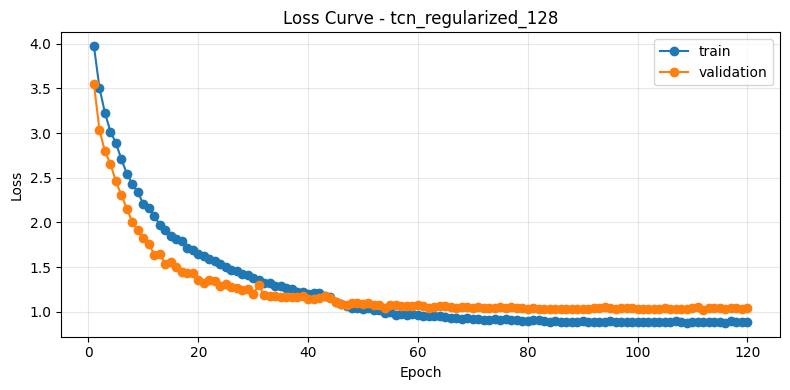

In [11]:
best_history_df = history_df[history_df['config_name'] == best_config['config_name']].copy()

plt.figure(figsize=(8, 4))
plt.plot(best_history_df['epoch'], best_history_df['train_loss'], marker='o', label='train')
plt.plot(best_history_df['epoch'], best_history_df['val_loss'], marker='o', label='validation')
plt.title(f"Loss Curve - {best_config['config_name']}")
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


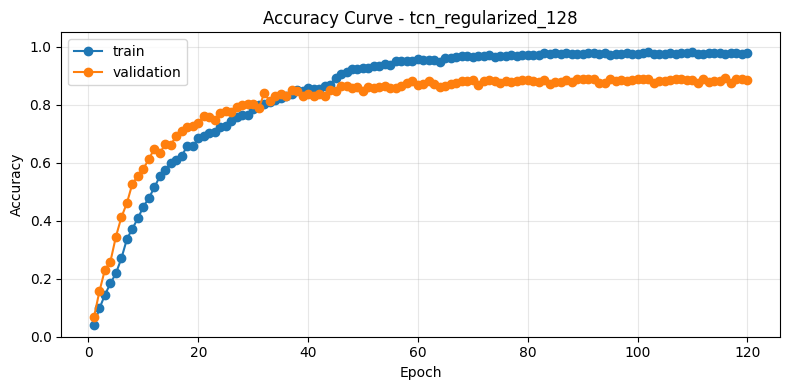

In [12]:
plt.figure(figsize=(8, 4))
plt.plot(best_history_df['epoch'], best_history_df['train_accuracy'], marker='o', label='train')
plt.plot(best_history_df['epoch'], best_history_df['val_accuracy'], marker='o', label='validation')
plt.title(f"Accuracy Curve - {best_config['config_name']}")
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim(0, 1.05)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


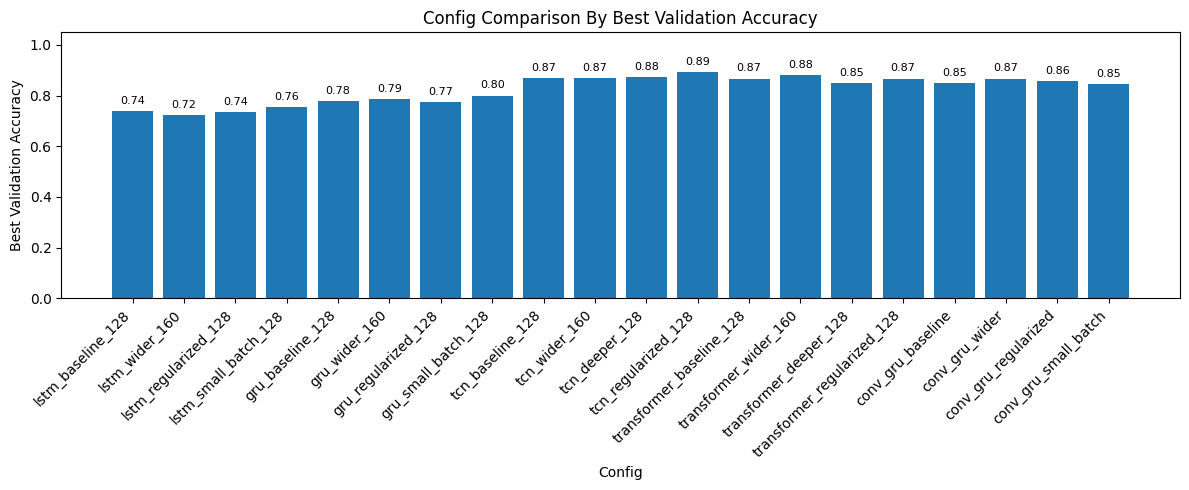

,model_type,best_val_accuracy
3,tcn,0.891791
4,transformer,0.882463
2,conv_gru_attention,0.867537
0,bigru_attention,0.800373
1,bilstm_attention,0.755597


In [ ]:
comparison_df = hyperparameter_results_df.sort_values('config_index')

plt.figure(figsize=(12, 5))
bars = plt.bar(comparison_df['config_name'], comparison_df['best_val_accuracy'])
plt.title('Config Comparison By Best Validation Accuracy')
plt.xlabel('Config')
plt.ylabel('Best Validation Accuracy')
plt.ylim(0, 1.05)
plt.xticks(rotation=45, ha='right')
for bar, value in zip(bars, comparison_df['best_val_accuracy']):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02, f'{value:.2f}', ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.show()

model_family_df = hyperparameter_results_df.groupby('model_type', as_index=False)['best_val_accuracy'].max()
display(model_family_df.sort_values('best_val_accuracy', ascending=False))

Predicted,again,bad,bathroom,book,bye,don't know,don't like,don't understand,don't want,drink,...,want,water,we,what,which,who,why,work,yes,you
Actual,,,,,,,,,,,,,,,,,,,,,
again,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
bad,0,5,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
bathroom,0,0,11,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
book,0,0,0,7,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
bye,0,0,0,0,6,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
don't know,0,0,0,0,0,4,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
don't like,0,0,0,0,0,0,9,0,0,0,...,0,0,0,0,0,0,0,0,0,0
don't understand,0,0,0,0,0,0,0,9,0,0,...,0,0,0,0,0,0,0,0,0,0
don't want,0,0,0,0,0,0,0,0,5,0,...,0,0,0,0,0,0,0,0,0,0


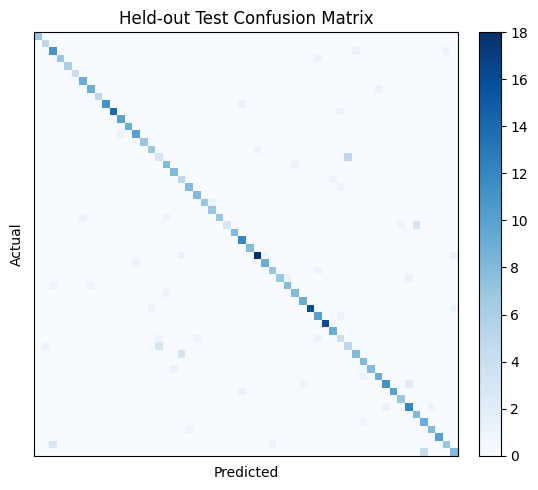

In [16]:
label_order = list(label_to_id.keys())
confusion = pd.crosstab(
    pd.Series(test_metrics['labels']).map(id_to_label),
    pd.Series(test_metrics['preds']).map(id_to_label),
    rownames=['Actual'],
    colnames=['Predicted'],
    dropna=False,
).reindex(index=label_order, columns=label_order, fill_value=0)

display(confusion)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(confusion.values, cmap='Blues')
ax.set_title('Held-out Test Confusion Matrix')
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_xticklabels([])
ax.set_yticklabels([])
ax.tick_params(axis='both', which='both', length=0)  # hide tick marks

ax.grid(False)

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()


In [17]:
confusion.to_csv('confusion_matrix.csv')

,label,accuracy,count
0,again,1.000000,7
1,bad,1.000000,5
2,bathroom,0.846154,13
3,book,0.875000,8
4,bye,1.000000,6
5,don't know,1.000000,4
6,don't like,1.000000,9
7,don't understand,0.900000,10
8,don't want,1.000000,5
9,drink,0.916667,12


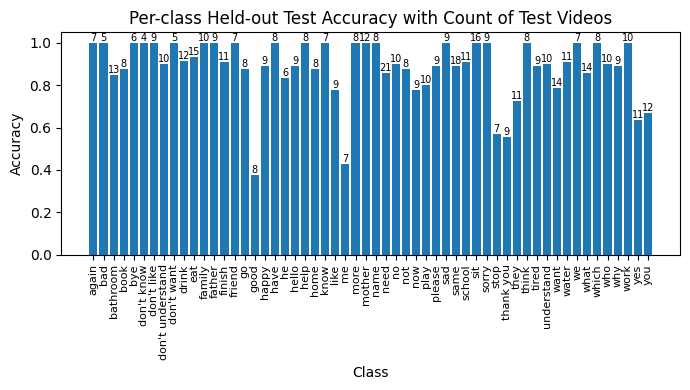

In [24]:
per_class = []
for label, class_id in label_to_id.items():
    mask = test_metrics['labels'] == class_id
    acc = (test_metrics['preds'][mask] == test_metrics['labels'][mask]).mean() if mask.any() else np.nan
    per_class.append({'label': label, 'accuracy': acc, 'count': int(mask.sum())})

per_class_df = pd.DataFrame(per_class)
display(per_class_df)

plt.figure(figsize=(7, 4))
bars = plt.bar(per_class_df['label'], per_class_df['accuracy'])
plt.title('Per-class Held-out Test Accuracy with Count of Test Videos')
plt.xlabel('Class')
plt.ylabel('Accuracy')
plt.ylim(0, 1.05)
plt.xticks(rotation=90, fontsize=8)
for bar, row in zip(bars, per_class_df.itertuples(index=False)):
    value = 0 if np.isnan(row.accuracy) else row.accuracy
    plt.text(bar.get_x() + bar.get_width() / 2, value, f'{row.count}', ha='center', va='bottom', fontsize=7)
plt.tight_layout()
plt.show()


## Smoke Test And Full Run

For a smoke test, set `SMOKE_TEST = True` in the setup cell and run the notebook end-to-end. That uses `NUM_EPOCHS = 2`, `PATIENCE = 2`, and only the first config, while still creating `models/best_model.pt`, `models/training_history.csv`, `models/hyperparameter_results.csv`, and the final graphs.

For the final run, delete the smoke-test `models/best_model.pt`, set `SMOKE_TEST = False`, keep `NUM_EPOCHS = 120`, `PATIENCE = 20`, and run all 20 configs across the 5 model families.

The winning checkpoint saves `model_type`, `model_config`, and `training_config`, so inference can rebuild the exact architecture that won instead of assuming every model is an LSTM.
